# Module 2: Principal Component Analysis (PCA)

This module will talk about a method for reducing the dimensionality of data in applications; namely, principal component analysis (PCA).

### Overview

Working with *big* data is difficult for a variety of reasons. Put simply, it is harder to analyze and interpret large amounts of data from both a practical perspective and a computational perspective. Thankfully, there are techniques to exploit the structure in high-dimensional data. For example, high-dimensional data oftentimes has features that are redundant. Moreover, some of these features can be explained by linear combinations of other features, and thus can be removed from the data. What this leads to is the ability to extract a low-dimensional substructure of the original high-dimensional data. PCA is a technique to do exactly this.

PCA is a well established technique that can help us identify simple patterns, latent factors, and structure in high-dimensional data. We now derive this algorithm from first principles.

## Problem Formulation

Let $(\Omega, \mathcal{F}, \mathbb{P})$ be a probability space and let 

$$
    X_n: \Omega \to \mathbb{R}^K
$$

be independent and identically distributed random vectors with finite second moments for $1 \le n \le N$. To make our notational life easy, we assume without loss of generality that each random vector $X_n$ has mean zero (apply a translation by $-\mathbb{E}[X_1] = -\mathbb{E}[X_n]$ for $1 \le n \le N$). Let $\omega_0 \in \Omega$ and consider the observed dataset 

$$
    \mathcal{D} = (X_1(\omega_0), \ldots, X_N(\omega_0)) =: (\mathbf{x}_1, \ldots, \mathbf{x}_N),
$$

where we denote

$$
    \mathbf{x}_n = (x_{n,1}, \ldots, x_{n,K}).
$$

We may view our data as the matrix

$$
    \mathcal{X} = (x_{n,k})_{1\le n \le N, 1 \le k \le K}.
$$

Let $M \in \mathbb{N}$ with $0 < M < K$. We are interested in finding the "best" orthogonal projection of the data vectors $\mathbf{x}_n$ onto an $M$-dimensional subspace $U$ of $\mathbb{R}^K$. We call a subspace $U$ corresponding to such an optimal projection a **principal subspace**. 

For any subspace $U$ of $\mathbb{R}^K$ with dimension $M$, we know that we may find an ordered orthonormal basis $(\mathbf{b}_1, \ldots, \mathbf{b}_M)$ of $U$. Put

$$
    \mathbf{z}_n := (\langle \mathbf{x}_n, \mathbf{b}_1\rangle_{\mathbb{R}^K}, \ldots, \langle \mathbf{x}_n, \mathbf{b}_M\rangle_{\mathbb{R}^K}) \in \mathbb{R}^M, \quad 1\le n \le N.
$$

We call the $\mathbf{z}_n$ the *codes* of $\mathbf{x}_n$ with respect to the subspace $U$ and orthonormal basis $(\mathbf{b}_1, \ldots, \mathbf{b}_M)$. For the given subspace $U$, we know that 

$$
    \tilde{\mathbf{x}}_n := \sum^M_{m=1} z_{n,m}\mathbf{b}_m = \operatorname{argmin}_{\mathbf{x} \in U}||\mathbf{x}_n - \mathbf{x}||^2_{\mathbb{R}^K}.
$$

Thus our main problem becomes *find an optimal subspace* $U$ *of* $\mathbb{R}^K$ *with* $\operatorname{dim}(U) = M$ *such that the average reconstruction loss*

$$
    J_M(U):=\frac{1}{N}\sum^N_{n=1} || \mathbf{x}_n - \tilde{\mathbf{x}}_n||^2_{\mathbb{R}^K}
$$

*is as small as possible.*  Note here that $J_M(U)$ admits the same value for any choice of orthonormal basis of $U$ by the uniqueness of the orthogonal projection.
 
Now let us define what we mean by *reconstruction loss*.

### Encoders, Decoders, and the Reconstruction Loss

Let $U \subseteq \mathbb{R}^K$ be an $M$-dimensional subspace, and let $(\mathbf{b}_1,\ldots,\mathbf{b}_M)$ be an orthonormal basis of $U$. 


<p align="center">
  <img src="figures/encoderdecoder.png" width="700">
</p>


Consider the **encoding map**

$$
\operatorname{Enc}_U:\mathbb{R}^K \to \mathbb{R}^M,
\qquad
\operatorname{Enc}_U(\mathbf{x})
=
(\langle \mathbf{x},\mathbf{b}_1\rangle,\ldots,\langle \mathbf{x},\mathbf{b}_M\rangle).
$$

From the code $\mathbf{z}_n=(z_{n,1},\ldots,z_{n,M})$, we recover an approximation of $\mathbf{x}_n$ by defining the **decoding map**

$$
\operatorname{Dec}_U:\mathbb{R}^M \to U,
\qquad
\operatorname{Dec}_U(z_1,\ldots,z_M)
=
\sum_{m=1}^M z_m \mathbf{b}_m.
$$

Applying the decoder to the code of $\mathbf{x}_n$ yields

$$
\tilde{\mathbf{x}}_n
:=
\operatorname{Dec}_U(\mathbf{z}_n)
=
\sum_{m=1}^M z_{n,m}\mathbf{b}_m
=
\sum_{m=1}^M
\langle \mathbf{x}_n,\mathbf{b}_m\rangle \mathbf{b}_m
=
P_U(\mathbf{x}_n),
$$

the orthogonal projection of $\mathbf{x}_n$ onto $U$.

We call $\tilde{\mathbf{x}}_n$ the **reconstruction** of $\mathbf{x}_n$. The quantity
$$
\|\mathbf{x}_n-\tilde{\mathbf{x}}_n\|_{\mathbb{R}^K}^2
$$

is called the **reconstruction error** of $\mathbf{x}_n$ (with respect to $U$); i.e., the squared Euclidean distance between the original data vector and its projection onto the subspace $U$. The average reconstruction error over the dataset is therefore

$$
J_M(U)
=
\frac{1}{N}\sum_{n=1}^N
\|\mathbf{x}_n-\tilde{\mathbf{x}}_n\|_{\mathbb{R}^K}^2.
$$

Thus, we can intuitively see that PCA seeks an $M$-dimensional subspace $U$ for which the encoding-decoding process loses as little information as possible on average.

### Minimizing the Reconstruction Loss

Suppose $(\mathbf{b}_1, \ldots, \mathbf{b}_K)$ is an ordered orthonormal basis for $\mathbb{R}^K$. Denote by $\mathbf{v} \otimes \mathbf{v}$ the outer product of the two vectors, and define

$$
        S:= \frac{1}{N}\mathcal{X}^t\mathcal{X} = \frac{1}{N}\sum^N_{n=1} (\mathbf{x}_n \otimes \mathbf{x}_n).
$$

For $M \in \mathbb{N}$, $1 \le M < K$, let $U = \operatorname{span}(\mathbf{b}_1, \ldots, \mathbf{b}_M)$, and observe that

$$
    \mathbf{x}_n - \tilde{\mathbf{x}}_n = \sum_{j = M+1}^K \langle \mathbf{x}_n, \mathbf{b}_j \rangle_{\mathbb{R}^K}\mathbf{b}_j = \sum_{j=M+1}^K (\mathbf{b}_j \otimes \mathbf{b}_j)\mathbf{x}_n = P_{U^\perp}(\mathbf{x}_n).
$$

But then,

$$
    \begin{align*}

        J_M(U) = \frac{1}{N} \sum^N_{n=1} || \mathbf{x}_n - \tilde{\mathbf{x}}_n ||^2_{\mathbb{R}^K} &= \frac{1}{N}\sum^N_{n=1} \left|\left| \sum^K_{j = M+1} \langle \mathbf{x}_n, \mathbf{b}_j \rangle_{\mathbb{R}^K} \mathbf{b}_j \right|\right|^2_{\mathbb{R}^K}\\
        &= \frac{1}{N} \sum^N_{n=1} \sum^K_{j = M+1} |\langle \mathbf{x}_n, \mathbf{b}_j \rangle_{\mathbb{R}^K}|^2\\
        &= \frac{1}{N} \sum^N_{n=1} \sum^K_{j = M+1} \langle \mathbf{b}_j, (\mathbf{x}_n \otimes \mathbf{x}_n)\mathbf{b}_j\rangle_{\mathbb{R}^K}\\
        &=  \sum^K_{j = M+1} \left\langle \mathbf{b}_j, \left(\frac{1}{N}\sum^N_{n=1} \mathbf{x}_n \otimes \mathbf{x}_n\right)\mathbf{b}_j\right\rangle_{\mathbb{R}^K}\\
        &=  \sum^K_{j = M+1} \langle \mathbf{b}_j, S\mathbf{b}_j \rangle_{\mathbb{R}^K}.
    \end{align*}
$$

 It is clear that $S \in \mathbb{R}^{K \times K}$ is positive semidefinite and symmetric. By the spectral theorem, we know there exists an orthonormal basis $\mathbf{q}_1, \ldots, \mathbf{q}_K$ of $\mathbb{R}^K$ that are the eigenvectors of $S$, with corresponding eigenvalues $\lambda_1 \ge  \cdots \ge \lambda_K \ge 0$. We make a couple of observations:

 1. We have that for $1 \le m \le K$,
 
 $$
 \mathbf{b}_m = \sum^K_{k=1} \langle \mathbf{b}_m, \mathbf{q}_k \rangle_{\mathbb{R}^K}\mathbf{q}_k \implies S\mathbf{b}_m = S\sum^K_{k=1} \langle \mathbf{b}_m, \mathbf{q}_k \rangle_{\mathbb{R}^K}\mathbf{q}_k = \sum^K_{k=1} \langle \mathbf{b}_m, \mathbf{q}_k \rangle_{\mathbb{R}^K} S\mathbf{q}_k = \sum^K_{k=1} \lambda_k \langle \mathbf{b}_m, \mathbf{q}_k \rangle_{\mathbb{R}^K} \mathbf{q}_k;
 $$
 
 2. Moreover, for $1 \le m \le K$,

 $$
    \langle S\mathbf{b}_m, \mathbf{b}_m\rangle_{\mathbb{R}^K} = \left\langle \sum^K_{k=1} \lambda_k \langle \mathbf{b}_m, \mathbf{q}_k \rangle_{\mathbb{R}^K} \mathbf{q}_k, \mathbf{b}_m \right\rangle_{\mathbb{R}^K} = \sum^K_{k=1} \lambda_k |\langle \mathbf{b}_m, \mathbf{q}_k \rangle_{\mathbb{R}^K}|^2.
 $$

 With these observations in mind, we establish that

 $$
    J_M(U) = \sum^K_{j = M+1}\sum^K_{k=1} \lambda_k|\langle \mathbf{b}_j, \mathbf{q}_k \rangle_{\mathbb{R}^K}|^2 = \sum^{K}_{k=1}\lambda_k\sum^K_{j = M+1} |\langle \mathbf{b}_j, \mathbf{q}_k \rangle_{\mathbb{R}^K}|^2 = \sum^K_{k=1}\lambda_k\alpha_k,
 $$

 where 

 $$
    \alpha_k:= \sum^K_{j = M+1}|\langle \mathbf{b}_j, \mathbf{q}_k \rangle_{\mathbb{R}^K}|^2 = || P_{U^\perp}(\mathbf{q}_k) ||^2_{\mathbb{R}^K} \le 1,
 $$

 as $P_{U^\perp}$ is a contraction. Thus we have that 

 $$
        0 \le \alpha_k \le 1, \quad 1 \le k \le K.
 $$

 Moreover, by Parseval's identity, we have

 $$
        \sum^K_{k=1} \alpha_k = \sum^K_{j = M+1} \sum^K_{k=1} |\langle \mathbf{b}_j, \mathbf{q}_k \rangle_{\mathbb{R}^K}|^2 = \sum^K_{j = M+1} || \mathbf{b}_j ||^2_{\mathbb{R}^K} = K- M.
 $$

So for every choice of $U$ with dimension $M$, we have that

$$
    0 \le \alpha_k \le 1, \quad 1 \le k \le K \quad \text{ and } \quad \sum^K_{k=1} \alpha_k = K-M.
$$

Our objective now is to minimize 

$$ 
    J_M(U) = \sum^K_{k=1}\lambda_k \alpha_k.
$$

Observe that by the ordering of the eigenvalues

$$
    \begin{align*}
         J_M(U) - \sum^K_{j = M+1} \lambda_j = \sum^K_{k=1}\lambda_k\alpha_k - \sum^K_{j =M+1}\lambda_j &= \sum^M_{k =1}\lambda_k\alpha_k - \sum^K_{j = M+1}\lambda_j(1-\alpha_j)\\
          &\ge \lambda_M\sum^M_{k=1}\alpha_k - \lambda_M\sum^K_{j = M+1}(1-\alpha_j)\\
          & = \lambda_M\left(\sum^K_{k=1}\alpha_k - (K-M)\right)\\
          & = 0.
    \end{align*}
$$

In particular, we have that for any subspace $U$ of $\mathbb{R}^K$ with $\operatorname{dim}(U) = M$,

$$
    J_M(U) \ge \sum^K_{j= M+1}\lambda_j.
$$

Note that this lower bound is independent of the choice of $U$. The next proposition shows that $J_M$ attains this lower bound.

**Proposition.** *Let* $M \in \mathbb{N}$ *such that* $1 \le M < K$*, and let* $(\mathbf{q}_1, \ldots, \mathbf{q}_K)$ *be the orthonormal basis of eigenvectors as we have above. Then for* $U^*:= \operatorname{span}(\mathbf{q}_1, \ldots, \mathbf{q}_M)$, *we have* 

$$
       J_M(U^*) = \sum^K_{j = M+1} \lambda_{j}; 
$$

*that is,* $J_M$ *attains its minimum at* $U^*$. *In particular,* $U^*$ *is a principal subspace.*

*Proof.* Simply observe that

$$
    J_M(U^*) = \sum^K_{j = M+1} \langle S\mathbf{q}_j, \mathbf{q}_j\rangle_{\mathbb{R}^K} = \sum^K_{j = M+1} \lambda_j || \mathbf{q}_j ||^2_{\mathbb{R}^K} = \sum^K_{j = M+1}\lambda_j,
$$

as desired. $\blacksquare$

# Probabilistic Principal Component Analysis (PPCA)

We now develop a latent-variable probabilistic perspective of PCA with the tools that we have established.

### The Probabilistic Approach

Let $(\Omega, \mathcal{F}, \mathbb{P})$ be a probability space, and let

$$
    Z: \Omega \to \mathbb{R}^M \quad \text{and} \quad \epsilon: \Omega \to \mathbb{R}^K
$$

be independent random vectors such that

$$
    Z \sim N(\mathbf{0}, I_M) \quad \text{and} \quad \epsilon \sim N(\mathbf{0}, \sigma^2I_K),
$$

where $\sigma >0$. For $\mathbf{\mu} \in \mathbb{R}^K$ and $W \in \mathbb{R}^{K\times M}$, we model the observed random vector $X$ by

$$
    X = WZ + \mathbf{\mu} + \epsilon,
$$

<p align="center">
  <img src="figures/latentdiagram.png" width="700">
</p>

where $Z$ is our **latent random vector**; i.e., the unobserved lower-dimensional source of variability underlying the observed random vector $X$, $\epsilon$ is the noise random vector that accounts for the variability in $X$ that is not explained by $Z$, and $\mathbf{\mu}$ is the mean vector that determines the center of the distribution of $X$.

We impose a simple probability distribution on the lower-dimensional latent space. In particular,

$$
    \mathbb{E}[Z] = 0 \quad \text{and} \quad \operatorname{Cov}(Z) = I_M.
$$

The matrix $W$ is responsible for transforming the standardized distribution into a distribution in the ambient space. In particular, the realizations of $WZ$ lie in the column space of $W$, which is a subspace of $\mathbb{R}^K$ of dimension at most $M$. We also assume that the observations deviate from this lower-dimensional structure according to additive Gaussian noise. Centering $X$ by $\boldsymbol{\mu}$ will make our lives easier when we eventually look at maximum likelihood. Notice that $W$ is not restricted to having orthonormal columns, since $W$ must be able to describe both the directions of the latent subspace and the magnitude of the variability in those directions; i.e., the extent to which realizations deviate from their mean along those directions. Requiring orthonormal columns would unnecessarily restrict the family of probability distributions our model could represent. We will ultimately show that the Gaussian assumption on $Z$ does not prevent us from recovering a classical principal subspace under suitable conditions.



### The Distribution of the Observed Random Vector

Our next objective is to determine the distribution of the observed random vector

$$
X = WZ + \boldsymbol{\mu} + \epsilon.
$$

To do so, we first establish a useful characterization of Gaussian random vectors. Recall that a real-valued random variable $Y$ is said to have a **degenerate Gaussian distribution** if there exists some $\mu \in \mathbb{R}$ such that $\mathbb{P}(Y = \mu) = 1$. In this case, we write $Y \sim N(\mu,0)$.

For a random vector $Y: \Omega \to \mathbb{R}^K$, we define its **characteristic function** $\varphi_Y: \mathbb{R}^K \to \mathbb{C}$ by

$$
\varphi_Y(\mathbf{t}) := \mathbb{E}[e^{i\langle Y,\mathbf{t}\rangle_{\mathbb{R}^K}}], \quad \mathbf{t}\in\mathbb{R}^K.
$$

Recall that a random vector $Y: \Omega \to \mathbb{R}^K$ has a Gaussian distribution with mean vector $\boldsymbol{\mu}$ and covariance matrix $\Sigma$ if and only if its characteristic function is given by

$$
\varphi_Y(\mathbf{t})
= \exp\left(i\langle \boldsymbol{\mu},\mathbf{t}\rangle_{\mathbb{R}^K} - \frac{1}{2}\langle \Sigma\mathbf{t},\mathbf{t}\rangle_{\mathbb{R}^K}\right),
\quad \mathbf{t}\in\mathbb{R}^K,
$$

where $\Sigma$ is a symmetric positive semidefinite matrix.

**Proposition.** *Let* $Y:\Omega\to\mathbb{R}^K$ *be a random vector. Then* $Y$ *is a Gaussian random vector if and only if* $\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}$ *is a possibly degenerate Gaussian random variable for every* $\mathbf{v}\in\mathbb{R}^K$.

*Proof.* Suppose $Y\sim N(\boldsymbol{\mu},\Sigma)$ and fix $\mathbf{v}\in\mathbb{R}^K$. Observe that for every $t\in\mathbb{R}$,

$$
\begin{align*}
\varphi_{\langle Y,\mathbf{v}\rangle}(t)
&= \mathbb{E}[e^{it\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}}]\\
&= \mathbb{E}[e^{i\langle Y,t\mathbf{v}\rangle_{\mathbb{R}^K}}]\\
&= \varphi_Y(t\mathbf{v})\\
&= \exp\left(it\langle \boldsymbol{\mu},\mathbf{v}\rangle_{\mathbb{R}^K}
-\frac{t^2}{2}\langle \Sigma\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}\right).
\end{align*}
$$

By the uniqueness theorem for characteristic functions, we have that

$$
\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}
\sim N\left(\langle \boldsymbol{\mu},\mathbf{v}\rangle_{\mathbb{R}^K},
\langle \Sigma\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}\right).
$$

Conversely, suppose that $\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}$ is a possibly degenerate Gaussian random variable for every $\mathbf{v}\in\mathbb{R}^K$. By taking $\mathbf{v}=\mathbf{e}_j$ for $1\le j\le K$, we see that each coordinate of $Y$ is Gaussian and hence has finite second moments. Thus, we may define

$$
\boldsymbol{\mu}:=\mathbb{E}[Y]
\quad \text{and} \quad
\Sigma:=\operatorname{Cov}(Y)
=\mathbb{E}[(Y-\boldsymbol{\mu})\otimes(Y-\boldsymbol{\mu})].
$$

For every $\mathbf{v}\in\mathbb{R}^K$, we have that

$$
\mathbb{E}[\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}]
=\langle \boldsymbol{\mu},\mathbf{v}\rangle_{\mathbb{R}^K}
$$

and

$$
\begin{align*}
\operatorname{Var}(\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K})
&=\mathbb{E}[|\langle Y-\boldsymbol{\mu},\mathbf{v}\rangle_{\mathbb{R}^K}|^2]\\
&=\mathbb{E}[\langle ((Y-\boldsymbol{\mu})\otimes(Y-\boldsymbol{\mu}))\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}]\\
&=\left\langle \mathbb{E}[(Y-\boldsymbol{\mu})\otimes(Y-\boldsymbol{\mu})]\mathbf{v},\mathbf{v}\right\rangle_{\mathbb{R}^K}\\
&=\langle \Sigma\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}.
\end{align*}
$$

Since $\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}$ is Gaussian by assumption, we have that

$$
\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}
\sim N\left(\langle \boldsymbol{\mu},\mathbf{v}\rangle_{\mathbb{R}^K},
\langle \Sigma\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}\right).
$$

Consequently,

$$
\begin{align*}
\varphi_Y(\mathbf{v})
&=\mathbb{E}[e^{i\langle Y,\mathbf{v}\rangle_{\mathbb{R}^K}}]\\
&=\varphi_{\langle Y,\mathbf{v}\rangle}(1)\\
&=\exp\left(i\langle \boldsymbol{\mu},\mathbf{v}\rangle_{\mathbb{R}^K}
-\frac{1}{2}\langle \Sigma\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}\right).
\end{align*}
$$

Thus, $Y\sim N(\boldsymbol{\mu},\Sigma)$, as desired. $\blacksquare$

We are now in a position to determine the distribution of our observed random vector $X$.

**Proposition.** *Let* $Z:\Omega\to\mathbb{R}^M$ *and* $\epsilon:\Omega\to\mathbb{R}^K$ *be independent random vectors such that*

$$
Z\sim N(\mathbf{0},I_M)
\quad \text{and} \quad
\epsilon\sim N(\mathbf{0},\sigma^2I_K),
$$

*where* $\sigma>0$. *For* $W\in\mathbb{R}^{K\times M}$ *and* $\boldsymbol{\mu}\in\mathbb{R}^K$, *put*

$$
X:=WZ+\boldsymbol{\mu}+\epsilon.
$$

*Then*

$$
X\sim N(\boldsymbol{\mu},WW^t+\sigma^2I_K).
$$

*Proof.* We first establish that $X$ is a Gaussian random vector. Fix $\mathbf{v}\in\mathbb{R}^K$ and observe that

$$
\begin{align*}
\langle X,\mathbf{v}\rangle_{\mathbb{R}^K}
&=\langle WZ+\boldsymbol{\mu}+\epsilon,\mathbf{v}\rangle_{\mathbb{R}^K}\\
&=\langle Z,W^t\mathbf{v}\rangle_{\mathbb{R}^M}
+\langle \boldsymbol{\mu},\mathbf{v}\rangle_{\mathbb{R}^K}
+\langle \epsilon,\mathbf{v}\rangle_{\mathbb{R}^K}.
\end{align*}
$$

Since $Z$ and $\epsilon$ are independent Gaussian random vectors, it follows from the previous proposition that $\langle Z,W^t\mathbf{v}\rangle_{\mathbb{R}^M}$ and $\langle \epsilon,\mathbf{v}\rangle_{\mathbb{R}^K}$ are independent, possibly degenerate Gaussian random variables. Since the sum of independent Gaussian random variables is Gaussian and translation preserves Gaussianity, we have that $\langle X,\mathbf{v}\rangle_{\mathbb{R}^K}$ is Gaussian. As $\mathbf{v}\in\mathbb{R}^K$ was arbitrary, it follows from the previous proposition that $X$ is Gaussian.

We now determine the mean vector and covariance matrix of $X$. By linearity of expectation,

$$
\mathbb{E}[X]
=W\mathbb{E}[Z]+\boldsymbol{\mu}+\mathbb{E}[\epsilon]
=\boldsymbol{\mu}.
$$

Recall that the covariance matrix of a random vector $Y$ with finite second moments is given by

$$
\operatorname{Cov}(Y):=
\mathbb{E}[(Y-\mathbb{E}[Y])\otimes(Y-\mathbb{E}[Y])].
$$

Consequently, by bilinearity of the outer product, we have

$$
\begin{align*}
\operatorname{Cov}(X)
&=\mathbb{E}[(WZ+\epsilon)\otimes(WZ+\epsilon)]\\
&=\mathbb{E}[(WZ)\otimes(WZ)+(WZ)\otimes\epsilon+\epsilon\otimes(WZ)+\epsilon\otimes\epsilon]\\
&=W\mathbb{E}[Z\otimes Z]W^t
+W\mathbb{E}[Z\otimes\epsilon]
+\mathbb{E}[\epsilon\otimes Z]W^t
+\mathbb{E}[\epsilon\otimes\epsilon].
\end{align*}
$$

By independence and the fact that $Z$ and $\epsilon$ have mean zero, we have that

$$
\mathbb{E}[Z\otimes\epsilon]
=\mathbb{E}[Z]\otimes\mathbb{E}[\epsilon]
=\mathbf{0}_{M\times K}
$$

and similarly,

$$
\mathbb{E}[\epsilon\otimes Z]=\mathbf{0}_{K\times M}.
$$

Moreover, since $Z$ and $\epsilon$ have mean zero, we have

$$
\mathbb{E}[Z\otimes Z]=\operatorname{Cov}(Z)=I_M
\quad \text{and} \quad
\mathbb{E}[\epsilon\otimes\epsilon]=\operatorname{Cov}(\epsilon)=\sigma^2I_K.
$$

Thus,

$$
\operatorname{Cov}(X)=WW^t+\sigma^2I_K.
$$

Since a Gaussian distribution is uniquely determined by its mean vector and covariance matrix, we conclude that

$$
X\sim N(\boldsymbol{\mu},WW^t+\sigma^2I_K),
$$

as desired. $\blacksquare$

**Remark.** Notice that the covariance matrix of $X$ is positive definite, and hence non-singular. Indeed, for any nonzero $\mathbf{v}\in\mathbb{R}^K$,

$$
\langle (WW^t+\sigma^2I_K)\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}
=\|W^t\mathbf{v}\|^2_{\mathbb{R}^M}
+\sigma^2\|\mathbf{v}\|^2_{\mathbb{R}^K}>0.
$$

Thus, although $WZ$ is a degenerate Gaussian random vector in $\mathbb{R}^K$ (covariance matrix is singular), the addition of the independent Gaussian noise $\epsilon$ ensures that $X$ has a nondegenerate Gaussian distribution. In particular, $X$ possesses a probability density with respect to Lebesgue measure on $\mathbb{R}^K$, which will allow us to formulate our maximum likelihood problem.

### Interpreting the Covariance Matrix

Put

$$
C:=\operatorname{Cov}(X)=WW^t+\sigma^2I_K.
$$

We see that the covariance matrix consists of two components: $WW^t$, which describes the variability introduced by the latent random vector $Z$, and $\sigma^2I_K$, which describes the variability introduced by the noise random vector $\epsilon$. In particular, for any unit vector $\mathbf{v}\in\mathbb{R}^K$, we have

$$
\begin{align*}
\operatorname{Var}(\langle X,\mathbf{v}\rangle_{\mathbb{R}^K})
&=\langle C\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}\\
&=\langle WW^t\mathbf{v},\mathbf{v}\rangle_{\mathbb{R}^K}+\sigma^2\\
&=\|W^t\mathbf{v}\|^2_{\mathbb{R}^M}+\sigma^2.
\end{align*}
$$

Now, if $\mathbf{v}$ is a unit vector in $\operatorname{Ran}(W)^\perp$, then $W^t\mathbf{v}=\mathbf{0}$, so that

$$
\operatorname{Var}(\langle X,\mathbf{v}\rangle_{\mathbb{R}^K})=\sigma^2.
$$

In particular, all variability in directions orthogonal to the column space of $W$ is attributed entirely to the noise random vector $\epsilon$.


### The Density of a Gaussian Random Vector

Before proceeding with maximum likelihood estimation, we must determine the probability density function of our observed random vector $X$. To this end, we establish a general result concerning nondegenerate Gaussian random vectors.

**Proposition.** *Suppose* $X:\Omega\to\mathbb{R}^K$ *is a Gaussian random vector with* $X\sim N(\boldsymbol{\mu},C)$, *where* $C$ *is positive definite. Then the probability density function of* $X$ *is given by*

$$
p_X(\mathbf{x})=\frac{1}{(2\pi)^{K/2}\det(C)^{1/2}}\exp\left(-\frac{1}{2}\langle C^{-1}(\mathbf{x}-\boldsymbol{\mu}),\mathbf{x}-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}\right).
$$

*Proof.* Since $C$ is symmetric and positive definite, by the spectral theorem there exists an orthonormal basis $(\mathbf{q}_1,\ldots,\mathbf{q}_K)$ of $\mathbb{R}^K$ consisting of eigenvectors of $C$, with corresponding eigenvalues $\lambda_1,\ldots,\lambda_K>0$. For $1\le k\le K$, put

$$
Y_k:=\langle X-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}.
$$

By our previous characterization of Gaussian random vectors, we know that

$$
Y_k\sim N(0,\langle C\mathbf{q}_k,\mathbf{q}_k\rangle_{\mathbb{R}^K})=N(0,\lambda_k).
$$

We claim that the random variables $Y_1,\ldots,Y_K$ are independent. To see this, put $Y:=(Y_1,\ldots,Y_K)$ and observe that for any $\mathbf{t}=(t_1,\ldots,t_K)\in\mathbb{R}^K$,

$$
\begin{align*}
\varphi_Y(\mathbf{t})
&=\mathbb{E}\left[\exp\left(i\sum_{k=1}^K t_kY_k\right)\right]\\
&=\mathbb{E}\left[\exp\left(i\left\langle X-\boldsymbol{\mu},\sum_{k=1}^K t_k\mathbf{q}_k\right\rangle_{\mathbb{R}^K}\right)\right]\\
&=\varphi_{X-\boldsymbol{\mu}}\left(\sum_{k=1}^K t_k\mathbf{q}_k\right)\\
&=\exp\left(-\frac{1}{2}\left\langle C\sum_{k=1}^K t_k\mathbf{q}_k,\sum_{k=1}^K t_k\mathbf{q}_k\right\rangle_{\mathbb{R}^K}\right)\\
&=\exp\left(-\frac{1}{2}\sum_{k=1}^K\lambda_kt_k^2\right)\\
&=\prod_{k=1}^K\exp\left(-\frac{1}{2}\lambda_kt_k^2\right)\\
&=\prod_{k=1}^K\varphi_{Y_k}(t_k).
\end{align*}
$$

Thus, by the characterization of independence via characteristic functions, the random variables $Y_1,\ldots,Y_K$ are independent. Consequently, the joint probability density function of $Y$ is given by

$$
\begin{align*}
p_Y(\mathbf{y})
&=\prod_{k=1}^K p_{Y_k}(y_k)\\
&=\prod_{k=1}^K\frac{1}{\sqrt{2\pi\lambda_k}}\exp\left(-\frac{y_k^2}{2\lambda_k}\right)\\
&=\frac{1}{(2\pi)^{K/2}\left(\prod_{k=1}^K\lambda_k\right)^{1/2}}
\exp\left(-\frac{1}{2}\sum_{k=1}^K\frac{y_k^2}{\lambda_k}\right).
\end{align*}
$$

Now consider the affine map $T:\mathbb{R}^K\to\mathbb{R}^K$ given by

$$
T(\mathbf{x}):=(\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_1\rangle_{\mathbb{R}^K},\ldots,\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_K\rangle_{\mathbb{R}^K}).
$$

Notice that $Y=T(X)$. Since $T$ is a composition of a translation and an orthogonal transformation, it preserves Lebesgue measure. Consequently, the probability density function of $X$ is given by $p_X=p_Y\circ T$. Thus,

$$
\begin{align*}
p_X(\mathbf{x})
&=p_Y(T(\mathbf{x}))\\
&=\frac{1}{(2\pi)^{K/2}\left(\prod_{k=1}^K\lambda_k\right)^{1/2}}
\exp\left(-\frac{1}{2}\sum_{k=1}^K\frac{|\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}|^2}{\lambda_k}\right).
\end{align*}
$$

It remains to express this density in terms of the covariance matrix $C$. First, recall that the determinant of a matrix is the product of its eigenvalues (counting multiplicities), so that

$$
\det(C)=\prod_{k=1}^K\lambda_k.
$$

Moreover, since $C\mathbf{q}_k=\lambda_k\mathbf{q}_k$, applying $C^{-1}$ to both sides yields

$$
\mathbf{q}_k=\lambda_k C^{-1}\mathbf{q}_k\implies C^{-1}\mathbf{q}_k=\frac{1}{\lambda_k}\mathbf{q}_k.
$$

In particular, $C^{-1}$ has the same eigenvectors as $C$, with corresponding eigenvalues $\lambda_1^{-1},\ldots,\lambda_K^{-1}$. Since $(\mathbf{q}_1,\ldots,\mathbf{q}_K)$ is an orthonormal basis of $\mathbb{R}^K$, we have that

$$
\mathbf{x}-\boldsymbol{\mu}=\sum_{k=1}^K\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}\mathbf{q}_k.
$$

Applying $C^{-1}$ to both sides, we obtain

$$
\begin{align*}
C^{-1}(\mathbf{x}-\boldsymbol{\mu})
&=\sum_{k=1}^K\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}C^{-1}\mathbf{q}_k\\
&=\sum_{k=1}^K\frac{1}{\lambda_k}\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}\mathbf{q}_k.
\end{align*}
$$

Consequently,

$$
\begin{align*}
\langle C^{-1}(\mathbf{x}-\boldsymbol{\mu}),\mathbf{x}-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}
&=\left\langle\sum_{k=1}^K\frac{1}{\lambda_k}\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}\mathbf{q}_k,\mathbf{x}-\boldsymbol{\mu}\right\rangle_{\mathbb{R}^K}\\
&=\sum_{k=1}^K\frac{1}{\lambda_k}\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}\langle\mathbf{q}_k,\mathbf{x}-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}\\
&=\sum_{k=1}^K\frac{|\langle\mathbf{x}-\boldsymbol{\mu},\mathbf{q}_k\rangle_{\mathbb{R}^K}|^2}{\lambda_k}.
\end{align*}
$$

Putting everything together, we conclude that

$$
p_X(\mathbf{x})=\frac{1}{(2\pi)^{K/2}\det(C)^{1/2}}\exp\left(-\frac{1}{2}\langle C^{-1}(\mathbf{x}-\boldsymbol{\mu}),\mathbf{x}-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}\right),
$$

as desired. $\blacksquare$

Returning to our probabilistic PCA model, recall that

$$
X=WZ+\boldsymbol{\mu}+\epsilon\sim N(\boldsymbol{\mu},WW^t+\sigma^2I_K).
$$

Since $C:=WW^t+\sigma^2I_K$ is positive definite, by the previous proposition we have that the probability density function of $X$ is given by

$$
p(\mathbf{x}\mid W,\boldsymbol{\mu},\sigma^2)=\frac{1}{(2\pi)^{K/2}\det(C)^{1/2}}\exp\left(-\frac{1}{2}\langle C^{-1}(\mathbf{x}-\boldsymbol{\mu}),\mathbf{x}-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}\right).
$$

Here, the notation $p(\mathbf{x}\mid W,\boldsymbol{\mu},\sigma^2)$ is used to emphasize the dependence of the probability density function on the parameters $W$, $\boldsymbol{\mu}$, and $\sigma^2$. We are now in a position to formulate our maximum likelihood estimation problem.

### Maximum Likelihood Estimation

Recall that under our probabilistic model,

$$
X \sim N(\boldsymbol{\mu}, WW^t + \sigma^2 I_K).
$$

For notational convenience, put $C := WW^t + \sigma^2 I_K$. Since $C$ is positive definite, the distribution of $X$ admits the probability density function

$$
p(\mathbf{x}\mid W,\boldsymbol{\mu},\sigma^2)
=
\frac{1}{(2\pi)^{K/2}\det(C)^{1/2}}
\exp\left(-\frac{1}{2}\langle C^{-1}(\mathbf{x}-\boldsymbol{\mu}),\mathbf{x}-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}\right).
$$

Suppose that $X_1,\ldots,X_N$ are independent and identically distributed random vectors having this distribution and that $\mathcal{D}=(\mathbf{x}_1,\ldots,\mathbf{x}_N)$ is our observed dataset. Our objective is to find the parameters $W,\boldsymbol{\mu},\sigma^2$ that maximize the likelihood of the observed dataset. By independence, the likelihood function is given by

$$
\begin{align*}
\mathcal{L}(W,\boldsymbol{\mu},\sigma^2)
&:= \prod_{n=1}^N p(\mathbf{x}_n\mid W,\boldsymbol{\mu},\sigma^2)\\
&= \frac{1}{(2\pi)^{NK/2}\det(C)^{N/2}}
\exp\left(-\frac{1}{2}\sum_{n=1}^N
\langle C^{-1}(\mathbf{x}_n-\boldsymbol{\mu}),\mathbf{x}_n-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}\right).
\end{align*}
$$

Since the logarithm is strictly increasing, maximizing the likelihood function is equivalent to maximizing the log-likelihood function

$$
\begin{align*}
\ell(W,\boldsymbol{\mu},\sigma^2)
&:= \log\mathcal{L}(W,\boldsymbol{\mu},\sigma^2)\\
&= -\frac{NK}{2}\log(2\pi)-\frac{N}{2}\log\det(C)
-\frac{1}{2}\sum_{n=1}^N
\langle C^{-1}(\mathbf{x}_n-\boldsymbol{\mu}),\mathbf{x}_n-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}.
\end{align*}
$$

Since the first term is independent of our parameters, maximizing the log-likelihood function is equivalent to minimizing the objective function

$$
J(W,\boldsymbol{\mu},\sigma^2)
:= \log\det(C)+\frac{1}{N}\sum_{n=1}^N
\langle C^{-1}(\mathbf{x}_n-\boldsymbol{\mu}),\mathbf{x}_n-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}.
$$

This is the optimization problem underlying probabilistic PCA.

#### Determining the Optimal Mean Vector

Notice that $C$ is independent of $\boldsymbol{\mu}$. Thus, for any fixed choice of $W$ and $\sigma^2$, minimizing $J$ with respect to $\boldsymbol{\mu}$ is equivalent to minimizing

$$
\frac{1}{N}\sum_{n=1}^N
\langle C^{-1}(\mathbf{x}_n-\boldsymbol{\mu}),\mathbf{x}_n-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}.
$$

The following proposition shows that the optimal choice of $\boldsymbol{\mu}$ is precisely the empirical mean of our observed dataset.

**Proposition.** *For any fixed* $W\in\mathbb{R}^{K\times M}$ *and* $\sigma>0$, *the function* $\boldsymbol{\mu}\mapsto J(W,\boldsymbol{\mu},\sigma^2)$ *attains its unique minimum at*

$$
\overline{\mathbf{x}}:=\frac{1}{N}\sum_{n=1}^N\mathbf{x}_n.
$$

*Proof.* Since $C$ is positive definite, $C$ has a square root so that

$$
\langle C^{-1}(\mathbf{x}_n-\boldsymbol{\mu}),\mathbf{x}_n-\boldsymbol{\mu}\rangle_{\mathbb{R}^K}
=\|C^{-1/2}(\mathbf{x}_n-\boldsymbol{\mu})\|^2_{\mathbb{R}^K}.
$$

Thus, it suffices to minimize

$$
\frac{1}{N}\sum_{n=1}^N\|C^{-1/2}(\mathbf{x}_n-\boldsymbol{\mu})\|^2_{\mathbb{R}^K}.
$$

By linearity of $C^{-1/2}$ and the fact that $\sum_{n=1}^N(\mathbf{x}_n-\overline{\mathbf{x}})=\mathbf{0}$, we have

$$
\begin{align*}
\frac{1}{N}\sum_{n=1}^N\|C^{-1/2}(\mathbf{x}_n-\boldsymbol{\mu})\|^2_{\mathbb{R}^K}
&=\frac{1}{N}\sum_{n=1}^N\|C^{-1/2}(\mathbf{x}_n-\overline{\mathbf{x}})+C^{-1/2}(\overline{\mathbf{x}}-\boldsymbol{\mu})\|^2_{\mathbb{R}^K}\\
&=\frac{1}{N}\sum_{n=1}^N\|C^{-1/2}(\mathbf{x}_n-\overline{\mathbf{x}})\|^2_{\mathbb{R}^K}
+\|C^{-1/2}(\overline{\mathbf{x}}-\boldsymbol{\mu})\|^2_{\mathbb{R}^K}\\
&\geq\frac{1}{N}\sum_{n=1}^N\|C^{-1/2}(\mathbf{x}_n-\overline{\mathbf{x}})\|^2_{\mathbb{R}^K},
\end{align*}
$$

with equality if and only if $\boldsymbol{\mu}=\overline{\mathbf{x}}$, by the invertibility of $C^{-1/2}$. $\blacksquare$

#### The Reduced Optimization Problem

By the previous proposition, we may eliminate $\boldsymbol{\mu}$ from our optimization problem by taking $\boldsymbol{\mu}=\overline{\mathbf{x}}$. For notational convenience, define the centered data vectors

$$
\mathbf{y}_n:=\mathbf{x}_n-\overline{\mathbf{x}},\quad 1\leq n\leq N.
$$

Our objective now is to minimize the function

$$
J(W,\sigma^2):=J(W,\overline{\mathbf{x}},\sigma^2)
=\log\det(C)+\frac{1}{N}\sum_{n=1}^N
\langle C^{-1}\mathbf{y}_n,\mathbf{y}_n\rangle_{\mathbb{R}^K},
$$

where $C=WW^t+\sigma^2I_K$. Notice that the empirical centering of our observed dataset has arisen naturally from maximum likelihood estimation, rather than being imposed as an assumption.

### Reformulating the Optimization Problem

Recall that our objective is to minimize the function

$$
J(W,\sigma^2)=\log\det(C)+\frac{1}{N}\sum_{n=1}^N\langle C^{-1}\mathbf{y}_n,\mathbf{y}_n\rangle_{\mathbb{R}^K},
$$

where $C=WW^t+\sigma^2I_K$ and $\mathbf{y}_n=\mathbf{x}_n-\overline{\mathbf{x}}$ for $1\le n\le N$. We would like to express our objective function in terms of the empirical covariance matrix

$$
S_c:=\frac{1}{N}\sum_{n=1}^N\mathbf{y}_n\otimes\mathbf{y}_n.
$$

To this end, we establish the following useful identity concerning the trace and outer products.

**Proposition.** *Let* $A\in\mathbb{R}^{K\times K}$ *and* $\mathbf{u},\mathbf{v}\in\mathbb{R}^K$. *Then*

$$
\operatorname{Tr}(A(\mathbf{u}\otimes\mathbf{v}))=\langle A\mathbf{u},\mathbf{v}\rangle_{\mathbb{R}^K}.
$$

*Proof.* Let $(\mathbf{e}_1,\ldots,\mathbf{e}_K)$ denote the standard orthonormal basis of $\mathbb{R}^K$. By definition of the trace and outer product, we have

$$
\begin{align*}
\operatorname{Tr}(A(\mathbf{u}\otimes\mathbf{v}))
&=\sum_{k=1}^K\langle A(\mathbf{u}\otimes\mathbf{v})\mathbf{e}_k,\mathbf{e}_k\rangle_{\mathbb{R}^K}\\
&=\sum_{k=1}^K\langle\mathbf{e}_k,\mathbf{v}\rangle_{\mathbb{R}^K}\langle A\mathbf{u},\mathbf{e}_k\rangle_{\mathbb{R}^K}\\
&=\left\langle A\mathbf{u},\sum_{k=1}^K\langle\mathbf{e}_k,\mathbf{v}\rangle_{\mathbb{R}^K}\mathbf{e}_k\right\rangle_{\mathbb{R}^K}\\
&=\langle A\mathbf{u},\mathbf{v}\rangle_{\mathbb{R}^K},
\end{align*}
$$

as desired. $\blacksquare$

Consequently, by the previous proposition and linearity of the trace, we have

$$
\begin{align*}
\frac{1}{N}\sum_{n=1}^N\langle C^{-1}\mathbf{y}_n,\mathbf{y}_n\rangle_{\mathbb{R}^K}
&=\frac{1}{N}\sum_{n=1}^N\operatorname{Tr}(C^{-1}(\mathbf{y}_n\otimes\mathbf{y}_n))\\
&=\operatorname{Tr}\left(C^{-1}\left(\frac{1}{N}\sum_{n=1}^N\mathbf{y}_n\otimes\mathbf{y}_n\right)\right)\\
&=\operatorname{Tr}(C^{-1}S_c).
\end{align*}
$$

Thus, our optimization problem reduces to minimizing the function

$$
J(W,\sigma^2)=\log\det(C)+\operatorname{Tr}(C^{-1}S_c).
$$

Notice that the dependence of our objective function on the observed dataset is now entirely captured by the empirical covariance matrix $S_c$.


### The Spectral Structure of the Covariance Matrix

Before attempting to minimize $J$, we first examine the restrictions imposed on the covariance matrix $C$ by our probabilistic model. Recall that

$$
C=WW^t+\sigma^2I_K.
$$

Since $WW^t$ is symmetric and positive semidefinite with $\operatorname{rank}(WW^t)=\operatorname{rank}(W)\le M$, by the spectral theorem there exists an orthonormal basis $(\mathbf{b}_1,\ldots,\mathbf{b}_K)$ of $\mathbb{R}^K$ consisting of eigenvectors of $WW^t$, with corresponding eigenvalues

$$
\gamma_1\ge\cdots\ge\gamma_M\ge\gamma_{M+1}=\cdots=\gamma_K=0.
$$

For each $1\le k\le K$, observe that

$$
C\mathbf{b}_k=(WW^t+\sigma^2I_K)\mathbf{b}_k=(\gamma_k+\sigma^2)\mathbf{b}_k.
$$

In particular, $C$ and $WW^t$ admit a common orthonormal basis of eigenvectors. Denote the corresponding eigenvalues of $C$ by $c_1,\ldots,c_K$, where

$$
c_k:=\gamma_k+\sigma^2=
\begin{cases}
\gamma_k+\sigma^2,&1\le k\le M,\\
\sigma^2,&M+1\le k\le K.
\end{cases}
$$

Thus, the eigenvalues of $C$ satisfy

$$
c_1\ge\cdots\ge c_M\ge c_{M+1}=\cdots=c_K=\sigma^2>0.
$$

This is the fundamental restriction imposed on the covariance matrix $C$ by our probabilistic model. In particular, we are attempting to model the covariance structure of our observed data by a positive definite matrix whose smallest $K-M$ eigenvalues coincide.

### Expressing the Objective Function in Terms of Eigenvalues and Eigenvectors

Since $c_1,\ldots,c_K$ are the eigenvalues of $C$, we have

$$
\log\det(C)=\log\left(\prod_{k=1}^K c_k\right)=\sum_{k=1}^K\log(c_k).
$$

Moreover, recall that the eigenvalues of $C^{-1}$ corresponding to the eigenvectors $\mathbf{b}_1,\ldots,\mathbf{b}_K$ are $c_1^{-1},\ldots,c_K^{-1}$, respectively. Thus, by the cyclic property of the trace and its invariance under a change of orthonormal basis, we have

$$
\begin{align*}
\operatorname{Tr}(C^{-1}S_c)
&=\operatorname{Tr}(S_cC^{-1})\\
&=\sum_{k=1}^K\langle S_cC^{-1}\mathbf{b}_k,\mathbf{b}_k\rangle_{\mathbb{R}^K}\\
&=\sum_{k=1}^K\frac{1}{c_k}\langle S_c\mathbf{b}_k,\mathbf{b}_k\rangle_{\mathbb{R}^K}.
\end{align*}
$$

Putting these observations together, we obtain

$$
J(W,\sigma^2)=\sum_{k=1}^K\left(\log(c_k)+\frac{1}{c_k}\langle S_c\mathbf{b}_k,\mathbf{b}_k\rangle_{\mathbb{R}^K}\right).
$$


Conversely, suppose $(\mathbf{b}_1,\ldots,\mathbf{b}_K)$ is an arbitrary orthonormal basis of $\mathbb{R}^K$ and suppose we are given scalars

$$
c_1\ge\cdots\ge c_M\ge c_{M+1}=\cdots=c_K=\sigma^2>0.
$$

We wish to find a matrix $W\in\mathbb{R}^{K\times M}$ such that the covariance matrix $C=WW^t+\sigma^2I_K$ has eigenvectors $\mathbf{b}_1,\ldots,\mathbf{b}_K$ with corresponding eigenvalues $c_1,\ldots,c_K$. Notice that if $C$ is such a covariance matrix, then for any $\mathbf{x}\in\mathbb{R}^K$,

$$
\begin{align*}
C\mathbf{x}
&=C\left(\sum_{k=1}^K\langle\mathbf{x},\mathbf{b}_k\rangle_{\mathbb{R}^K}\mathbf{b}_k\right)\\
&=\sum_{k=1}^K c_k\langle\mathbf{x},\mathbf{b}_k\rangle_{\mathbb{R}^K}\mathbf{b}_k\\
&=\sum_{k=1}^K c_k(\mathbf{b}_k\otimes\mathbf{b}_k)\mathbf{x}.
\end{align*}
$$

Since $\mathbf{x}$ was arbitrary, we necessarily have that

$$
C=\sum_{k=1}^K c_k(\mathbf{b}_k\otimes\mathbf{b}_k).
$$

Moreover, since $I_K=\sum_{k=1}^K\mathbf{b}_k\otimes\mathbf{b}_k$, we must have

$$
\begin{align*}
WW^t
&=C-\sigma^2I_K\\
&=\sum_{k=1}^K(c_k-\sigma^2)(\mathbf{b}_k\otimes\mathbf{b}_k)\\
&=\sum_{k=1}^M(c_k-\sigma^2)(\mathbf{b}_k\otimes\mathbf{b}_k),
\end{align*}
$$

where the last equality follows from the fact that $c_k=\sigma^2$ for $M+1\le k\le K$. Now, recall that for any matrix $W=[\mathbf{w}_1,\ldots,\mathbf{w}_M]\in\mathbb{R}^{K\times M}$, we have

$$
WW^t=\sum_{k=1}^M\mathbf{w}_k\otimes\mathbf{w}_k.
$$

Thus, since $c_k-\sigma^2\ge 0$ for $1\le k\le M$, it suffices to take

$$
\mathbf{w}_k:=\sqrt{c_k-\sigma^2}\mathbf{b}_k,\quad 1\le k\le M;
$$

that is,

$$
W=[\sqrt{c_1-\sigma^2}\mathbf{b}_1,\ldots,\sqrt{c_M-\sigma^2}\mathbf{b}_M].
$$

Indeed, for this choice of $W$, we have

$$
\begin{align*}
C=WW^t+\sigma^2I_K
&=\sum_{k=1}^M(c_k-\sigma^2)(\mathbf{b}_k\otimes\mathbf{b}_k)+\sigma^2\sum_{k=1}^K\mathbf{b}_k\otimes\mathbf{b}_k\\
&=\sum_{k=1}^K c_k(\mathbf{b}_k\otimes\mathbf{b}_k).
\end{align*}
$$

In particular, $C\mathbf{b}_k=c_k\mathbf{b}_k$ for $1\le k\le K$, as desired.

We have therefore established that every covariance matrix of the form $C=WW^t+\sigma^2I_K$ has eigenvalues satisfying the above constraints and, conversely, that every choice of eigenvalues satisfying these constraints and every choice of orthonormal basis can be realized by an appropriate choice of $W$ and $\sigma^2$.

Consequently, minimizing the objective function $J$ over the parameters $W$ and $\sigma^2$ is equivalent to minimizing the expression

$$
\sum_{k=1}^K\left(\log(c_k)+\frac{1}{c_k}\langle S_c\mathbf{b}_k,\mathbf{b}_k\rangle_{\mathbb{R}^K}\right)
$$

over all orthonormal bases $(\mathbf{b}_1,\ldots,\mathbf{b}_K)$ of $\mathbb{R}^K$ and all collections of scalars satisfying

$$
c_1\ge\cdots\ge c_M\ge c_{M+1}=\cdots=c_K>0.
$$


We may therefore separate our optimization problem into two parts:

1. Determine the optimal choice of eigenvectors $\mathbf{b}_1,\ldots,\mathbf{b}_K$ for a fixed admissible choice of eigenvalues $c_1,\ldots,c_K$.
2. Determine the optimal choice of eigenvalues $c_1,\ldots,c_K$ subject to the constraints imposed by our probabilistic model.

Since $S_c$ is symmetric and positive semidefinite, let $(\mathbf{q}_1,\ldots,\mathbf{q}_K)$ be an orthonormal basis of $\mathbb{R}^K$ consisting of eigenvectors of $S_c$, with corresponding eigenvalues

$$
\lambda_1\ge\cdots\ge\lambda_K\ge 0.
$$

As we will establish, for any fixed admissible choice of eigenvalues $c_1,\ldots,c_K$, an optimal choice of eigenvectors for $C$ is given by $\mathbf{b}_k=\mathbf{q}_k$ for $1\le k\le K$. This will reduce our optimization problem to minimizing the expression

$$
\sum_{k=1}^K\left(\log(c_k)+\frac{\lambda_k}{c_k}\right)
$$

subject to the constraints

$$
c_1\ge\cdots\ge c_M\ge c_{M+1}=\cdots=c_K=\sigma^2>0.
$$


### Determining the Optimal Eigenvectors

Fix an admissible collection of eigenvalues

$$
c_1\ge\cdots\ge c_M\ge c_{M+1}=\cdots=c_K=\sigma^2>0.
$$

Since the eigenvalues are fixed, the quantity $\log\det(C)$ is constant. Thus, it suffices to minimize $\operatorname{Tr}(C^{-1}S_c)$ over all orthonormal bases $(\mathbf{b}_1,\ldots,\mathbf{b}_K)$ of eigenvectors of $C$. The following proposition shows that we may solve this problem by appealing to our previous results concerning classical PCA.

**Proposition.** *Let* $S_c$ *be the empirical covariance matrix with eigenvalues*

$$
\lambda_1\ge\cdots\ge\lambda_K\ge 0
$$

*and corresponding orthonormal eigenvectors* $(\mathbf{q}_1,\ldots,\mathbf{q}_K)$. *For any fixed admissible collection of eigenvalues* $c_1,\ldots,c_K$, *the quantity* $\operatorname{Tr}(C^{-1}S_c)$ *is minimized by taking*

$$
C=\sum_{k=1}^K c_k(\mathbf{q}_k\otimes\mathbf{q}_k).
$$

*In particular, the minimum value is given by*

$$
\sum_{k=1}^K\frac{\lambda_k}{c_k}.
$$

*Proof.* Let $(\mathbf{b}_1,\ldots,\mathbf{b}_K)$ be an orthonormal basis of eigenvectors of $C$ with corresponding eigenvalues $c_1,\ldots,c_K$. For each $1\le j<K$, put

$$
U_j:=\operatorname{span}(\mathbf{b}_1,\ldots,\mathbf{b}_j).
$$

By the spectral theorem, we have that

$$
C^{-1}=\sum_{k=1}^K\frac{1}{c_k}(\mathbf{b}_k\otimes\mathbf{b}_k).
$$

We claim that we may equivalently express $C^{-1}$ as

$$
C^{-1}=\frac{1}{c_1}I_K+\sum_{j=1}^{K-1}\left(\frac{1}{c_{j+1}}-\frac{1}{c_j}\right)P_{U_j^\perp}.
$$

Indeed, for each $1\le k\le K$, applying the right-hand side to $\mathbf{b}_k$ yields

$$
\begin{align*}
\frac{1}{c_1}\mathbf{b}_k+\sum_{j=1}^{K-1}\left(\frac{1}{c_{j+1}}-\frac{1}{c_j}\right)P_{U_j^\perp}(\mathbf{b}_k)
&=\frac{1}{c_1}\mathbf{b}_k+\sum_{j=1}^{k-1}\left(\frac{1}{c_{j+1}}-\frac{1}{c_j}\right)\mathbf{b}_k\\
&=\frac{1}{c_k}\mathbf{b}_k\\
&=C^{-1}\mathbf{b}_k,
\end{align*}
$$

where the second equality follows from the telescoping sum, with the sum understood to be zero when $k=1$. Since $(\mathbf{b}_1,\ldots,\mathbf{b}_K)$ is a basis of $\mathbb{R}^K$, the claimed identity follows. Consequently, by linearity of the trace, we have

$$
\operatorname{Tr}(C^{-1}S_c)
=\frac{1}{c_1}\operatorname{Tr}(S_c)+\sum_{j=1}^{K-1}\left(\frac{1}{c_{j+1}}-\frac{1}{c_j}\right)\operatorname{Tr}(P_{U_j^\perp}S_c).
$$

However, by our previous proposition concerning the trace and outer products, we have

$$
\begin{align*}
\operatorname{Tr}(P_{U_j^\perp}S_c)
&=\frac{1}{N}\sum_{n=1}^N\operatorname{Tr}(P_{U_j^\perp}(\mathbf{y}_n\otimes\mathbf{y}_n))\\
&=\frac{1}{N}\sum_{n=1}^N\langle P_{U_j^\perp}(\mathbf{y}_n),\mathbf{y}_n\rangle_{\mathbb{R}^K}\\
&=\frac{1}{N}\sum_{n=1}^N\|P_{U_j^\perp}(\mathbf{y}_n)\|^2_{\mathbb{R}^K}\\
&=\frac{1}{N}\sum_{n=1}^N\|(I_K-P_{U_j})(\mathbf{y}_n)\|^2_{\mathbb{R}^K}\\
&=\frac{1}{N}\sum_{n=1}^N\|\mathbf{y}_n-P_{U_j}(\mathbf{y}_n)\|^2_{\mathbb{R}^K}\\
&=J_j(U_j),
\end{align*}
$$

where we have used the fact that $P_{U_j^\perp}=I_K-P_{U_j}$ and where $J_j(U_j)$ denotes the classical average reconstruction loss associated with the subspace $U_j$ and the centered dataset $(\mathbf{y}_1,\ldots,\mathbf{y}_N)$. Thus, we obtain

$$
\operatorname{Tr}(C^{-1}S_c)
=\frac{1}{c_1}\operatorname{Tr}(S_c)+\sum_{j=1}^{K-1}\left(\frac{1}{c_{j+1}}-\frac{1}{c_j}\right)J_j(U_j).
$$

Notice that the first term is independent of the choice of orthonormal basis. Moreover, since $c_1\ge\cdots\ge c_K>0$, we have

$$
\frac{1}{c_{j+1}}-\frac{1}{c_j}\ge 0,\quad 1\le j<K.
$$

Recall from our study of classical PCA that, for each $1\le j<K$, the reconstruction loss $J_j(U_j)$ is minimized by taking

$$
U_j=\operatorname{span}(\mathbf{q}_1,\ldots,\mathbf{q}_j).
$$

In particular, by taking $\mathbf{b}_k=\mathbf{q}_k$ for $1\le k\le K$, we simultaneously minimize every reconstruction loss appearing in the above expression. Hence, this choice of orthonormal basis minimizes $\operatorname{Tr}(C^{-1}S_c)$. For this choice, we have

$$
\begin{align*}
\operatorname{Tr}(C^{-1}S_c)
&=\sum_{k=1}^K\frac{1}{c_k}\langle S_c\mathbf{q}_k,\mathbf{q}_k\rangle_{\mathbb{R}^K}\\
&=\sum_{k=1}^K\frac{\lambda_k}{c_k},
\end{align*}
$$

as desired. $\blacksquare$

An interesting consequence of the above proof is that the problem of determining the optimal eigenvectors of $C$ in probabilistic PCA reduces to minimizing a nonnegative weighted sum of classical PCA reconstruction losses.

### Reduction to an Optimization Problem over the Eigenvalues

By the previous proposition, for any fixed admissible collection of eigenvalues $c_1,\ldots,c_K$, we may take

$$
C=\sum_{k=1}^K c_k(\mathbf{q}_k\otimes\mathbf{q}_k).
$$

Hence, our optimization problem reduces to minimizing the function

$$
F(c_1,\ldots,c_K):=\sum_{k=1}^K\left(\log(c_k)+\frac{\lambda_k}{c_k}\right)
$$

subject to the constraints

$$
c_1\ge\cdots\ge c_M\ge c_{M+1}=\cdots=c_K=\sigma^2>0.
$$

Since $c_k=\sigma^2$ for $M+1\le k\le K$, we may equivalently minimize the function

$$
\begin{align*}
G(c_1,\ldots,c_M,\sigma^2)
&:=F(c_1,\ldots,c_M,\sigma^2,\ldots,\sigma^2)\\
&=\sum_{k=1}^M\left(\log(c_k)+\frac{\lambda_k}{c_k}\right)
+(K-M)\log(\sigma^2)+\frac{1}{\sigma^2}\sum_{k=M+1}^K\lambda_k
\end{align*}
$$

subject to the constraints

$$
c_1\ge\cdots\ge c_M\ge\sigma^2>0.
$$

We have therefore reduced our original maximum likelihood estimation problem to an optimization problem involving only $M+1$ scalar variables.



### Determining the Optimal Eigenvalues and Noise Variance

To solve this optimization problem, recall the elementary inequality

$$
\log(t)\le t-1,\quad t>0,
$$

with equality if and only if $t=1$. In particular, for any $a,b>0$, taking $t=a/b$ yields

$$
\log\left(\frac{a}{b}\right)\le\frac{a}{b}-1
\implies \log(b)+\frac{a}{b}\ge\log(a)+1,
$$

with equality if and only if $a=b$.

For notational convenience, put

$$
\overline{\lambda}:=\frac{1}{K-M}\sum_{k=M+1}^K\lambda_k.
$$

Suppose first that $\overline{\lambda}>0$. Since $\lambda_1\ge\cdots\ge\lambda_K\ge 0$, it follows that $\lambda_k>0$ for $1\le k\le M$. We may rewrite our objective function as

$$
G(c_1,\ldots,c_M,\sigma^2)
=\sum_{k=1}^M\left(\log(c_k)+\frac{\lambda_k}{c_k}\right)
+(K-M)\left(\log(\sigma^2)+\frac{\overline{\lambda}}{\sigma^2}\right).
$$

Applying the above inequality to each summand, we obtain

$$
\begin{align*}
G(c_1,\ldots,c_M,\sigma^2)
&=\sum_{k=1}^M\left(\log(c_k)+\frac{\lambda_k}{c_k}\right)
+(K-M)\left(\log(\sigma^2)+\frac{\overline{\lambda}}{\sigma^2}\right)\\
&\ge\sum_{k=1}^M(\log(\lambda_k)+1)
+(K-M)(\log(\overline{\lambda})+1)\\
&=\sum_{k=1}^M\log(\lambda_k)+(K-M)\log(\overline{\lambda})+K,
\end{align*}
$$

with equality if and only if

$$
c_k=\lambda_k,\quad 1\le k\le M,
\quad \text{and} \quad
\sigma^2=\overline{\lambda}.
$$

It remains to verify that this choice of parameters satisfies our constraints. By the ordering of the eigenvalues of $S_c$, we have

$$
\overline{\lambda}
=\frac{1}{K-M}\sum_{k=M+1}^K\lambda_k
\le\frac{1}{K-M}\sum_{k=M+1}^K\lambda_M
=\lambda_M.
$$

Consequently,

$$
\lambda_1\ge\cdots\ge\lambda_M\ge\overline{\lambda}>0,
$$

so that our choice of parameters is admissible. Thus, $G$ attains its unique minimum at

$$
c_k^*=\lambda_k,\quad 1\le k\le M,
\quad \text{and} \quad
(\sigma^*)^2=\frac{1}{K-M}\sum_{k=M+1}^K\lambda_k.
$$

We now consider the case where $\overline{\lambda}=0$. Since $S_c$ is positive semidefinite, this is equivalent to $\lambda_{M+1}=\cdots=\lambda_K=0$. For any $t>0$, take

$$
c_k=\lambda_k+t,\quad 1\le k\le M,
\quad \text{and} \quad
\sigma^2=t.
$$

Notice that these choices satisfy our constraints. Moreover,

$$
G(\lambda_1+t,\ldots,\lambda_M+t,t)
=\sum_{k=1}^M\left(\log(\lambda_k+t)+\frac{\lambda_k}{\lambda_k+t}\right)
+(K-M)\log(t).
$$

As $t\to 0^+$, each term in the summation either converges to a finite value or tends to $-\infty$, while $(K-M)\log(t)\to-\infty$. Consequently,

$$
\lim_{t\to 0^+}G(\lambda_1+t,\ldots,\lambda_M+t,t)=-\infty.
$$

Thus, when $\overline{\lambda}=0$, the log-likelihood function is unbounded above, and hence no maximum likelihood estimator exists within our parameter space.

### Recovering the Optimal Parameters

Suppose that $\overline{\lambda}>0$. Recall from our previous construction that, given an admissible collection of eigenvalues $c_1,\ldots,c_K$ and corresponding orthonormal eigenvectors $\mathbf{b}_1,\ldots,\mathbf{b}_K$, we may recover a corresponding matrix $W$ by taking

$$
W=[\sqrt{c_1-\sigma^2}\mathbf{b}_1,\ldots,\sqrt{c_M-\sigma^2}\mathbf{b}_M].
$$

Since we have established that an optimal choice of eigenvectors is given by $\mathbf{b}_k=\mathbf{q}_k$ for $1\le k\le K$ and that the optimal eigenvalues satisfy $c_k^*=\lambda_k$ for $1\le k\le M$, an optimal choice of $W$ is given by

$$
W^*=[\sqrt{\lambda_1-(\sigma^*)^2}\mathbf{q}_1,\ldots,\sqrt{\lambda_M-(\sigma^*)^2}\mathbf{q}_M].
$$

For notational convenience, put

$$
Q_M:=[\mathbf{q}_1,\ldots,\mathbf{q}_M]
\quad \text{and} \quad
\Lambda_M:=\operatorname{diag}(\lambda_1,\ldots,\lambda_M).
$$

We may equivalently express $W^*$ as

$$
W^*=Q_M\left(\Lambda_M-(\sigma^*)^2I_M\right)^{1/2}.
$$

Combining our results, we obtain the following theorem.

**Theorem.** *Let* $\mathcal{D}=(\mathbf{x}_1,\ldots,\mathbf{x}_N)$ *be an observed dataset with empirical mean* $\overline{\mathbf{x}}$ *and empirical covariance matrix* $S_c$. *Let* $\lambda_1\ge\cdots\ge\lambda_K\ge 0$ *be the eigenvalues of* $S_c$ *with corresponding orthonormal eigenvectors* $(\mathbf{q}_1,\ldots,\mathbf{q}_K)$. *If* $\sum_{k=M+1}^K\lambda_k>0$, *then a maximum likelihood estimate for the parameters of our probabilistic PCA model is given by*

$$
\boldsymbol{\mu}^*=\frac{1}{N}\sum_{n=1}^N\mathbf{x}_n,
$$

$$
(\sigma^*)^2=\frac{1}{K-M}\sum_{k=M+1}^K\lambda_k,
$$

*and*

$$
W^*=Q_M\left(\Lambda_M-(\sigma^*)^2I_M\right)^{1/2}.
$$

*If* $\sum_{k=M+1}^K\lambda_k=0$, *then no maximum likelihood estimator exists within our parameter space.*

**Remark.** Notice that the optimal choice of $W$ need not be unique. Indeed, for any orthogonal matrix $R\in\mathbb{R}^{M\times M}$, we have

$$
(W^*R)(W^*R)^t=W^*RR^t(W^*)^t=W^*(W^*)^t.
$$

Since the likelihood function depends on $W$ only through $WW^t$, it follows that $W^*R$ is also an optimal choice of $W$. This reflects the fact that the choice of coordinates in the latent space is not uniquely determined by the distribution of the observed random vector $X$.

### The Connection to Classical PCA

Recall from our study of classical PCA that

$$
U^*=\operatorname{span}(\mathbf{q}_1,\ldots,\mathbf{q}_M)
$$

is a principal subspace for the centered dataset $(\mathbf{y}_1,\ldots,\mathbf{y}_N)$, and that the minimum average reconstruction loss is given by

$$
J_M(U^*)=\sum_{k=M+1}^K\lambda_k.
$$

Suppose that $\overline{\lambda}>0$, so that our maximum likelihood estimates exist. By the preceding theorem, we have

$$
(\sigma^*)^2
=\frac{1}{K-M}\sum_{k=M+1}^K\lambda_k
=\frac{J_M(U^*)}{K-M}.
$$

In particular, the estimated noise variance in probabilistic PCA is precisely the minimum average reconstruction loss in classical PCA divided by the number of discarded dimensions.

Moreover, if $\lambda_M>(\sigma^*)^2$, then the matrix

$$
\left(\Lambda_M-(\sigma^*)^2I_M\right)^{1/2}
$$

is invertible. Consequently,

$$
\operatorname{Ran}(W^*)
=\operatorname{Ran}(Q_M)
=\operatorname{span}(\mathbf{q}_1,\ldots,\mathbf{q}_M)
=U^*.
$$

Thus, under this condition, probabilistic PCA recovers a classical principal subspace through maximum likelihood estimation.


### Python Implementation

We now implement PCA following the theory we have just established. We now implement PCA following the theory we have just established. In practice, since the population mean is generally unknown, we first center our observed dataset by its empirical mean and apply PCA to the resulting centered data vectors. After decoding, we restore the empirical mean to obtain our reconstructed observations.

In [1]:
#Importing needed libraries

import numpy as np 
import matplotlib.pyplot as plt

In [2]:
#Computing the empirical covariance matrix

def center_data(X):
    mean = np.mean(X, axis=0)
    Y = X - mean

    return Y, mean


def covariance_matrix(Y):
    N = Y.shape[0]
    S = (1 / N) * Y.T @ Y

    return S

In [3]:
#Computing eigenvalues and eigenvectors of the empirical covariance matrix

def spectral_decomposition(S):
    eigenvalues, eigenvectors = np.linalg.eigh(S)

    #Getting the eigen-data in decreasing order
    eigenvalues = eigenvalues[::-1]
    eigenvectors = eigenvectors[:, ::-1]

    return eigenvalues, eigenvectors

In [4]:
#Creating the encoder and decoder

def encode(Y, B):
    Z = Y @ B

    return Z


def decode(Z, B):
    Y_reconstructed = Z @ B.T

    return Y_reconstructed

In [5]:
#Creating the reconstruction loss

def reconstruction_loss(X, X_reconstructed):
    N = X.shape[0]

    residuals = X - X_reconstructed
    loss = (1 / N) * np.sum(residuals**2)

    return loss

In [6]:
#The PCA function

def PCA(X, M):
    
    N, K = X.shape

    if not 1 <= M <= K:
        raise ValueError("M must satisfy 1 <= M <= K.")

    # Center the observed dataset
    Y, mean = center_data(X)

    # Construct the empirical covariance matrix
    S = covariance_matrix(Y)

    # Obtain the eigenvalues and eigenvectors
    eigenvalues, eigenvectors = spectral_decomposition(S)

    # Construct an orthonormal basis of the principal subspace
    B = eigenvectors[:, :M]

    # Encode the centered observations
    Z = encode(Y, B)

    # Decode the observations and restore the empirical mean
    X_reconstructed = decode(Z, B) + mean

    # Compute the average reconstruction loss
    loss = reconstruction_loss(X, X_reconstructed)

    return B, Z, X_reconstructed, loss, eigenvalues

### Visualizing the Results

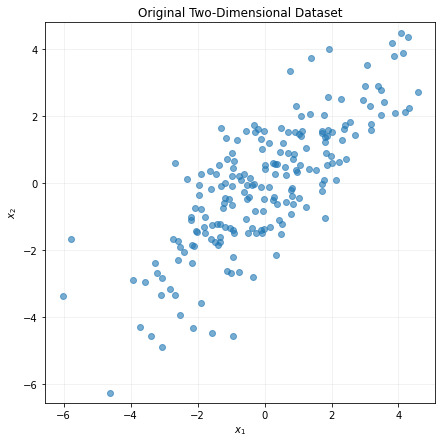

In [10]:
#Generating a 2D toy dataset with variability concentrated in one dimension

rng = np.random.default_rng(42)

N = 200

mean = np.array([0, 0])

Sigma = np.array([
    [4, 3],
    [3, 4]
])

X = rng.multivariate_normal(mean, Sigma, size=N)

#Visualizing the data

plt.figure(figsize=(7, 7))

plt.scatter(X[:, 0], X[:, 1], alpha=0.6)

plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("Original Two-Dimensional Dataset")

plt.axis("equal")
plt.grid(alpha=0.2)
plt.show()

In [11]:
#Applying PCA to the data

M = 1

B, Z, X_reconstructed, loss, eigenvalues = PCA(X, M)

print("Eigenvalues:", eigenvalues)
print("Principal direction:", B[:, 0])
print("Original data shape:", X.shape)
print("Encoded data shape:", Z.shape)
print("Reconstructed data shape:", X_reconstructed.shape)
print("Average reconstruction loss:", loss)

Eigenvalues: [6.81226064 0.83174025]
Principal direction: [-0.72395887 -0.68984313]
Original data shape: (200, 2)
Encoded data shape: (200, 1)
Reconstructed data shape: (200, 2)
Average reconstruction loss: 0.8317402496062164


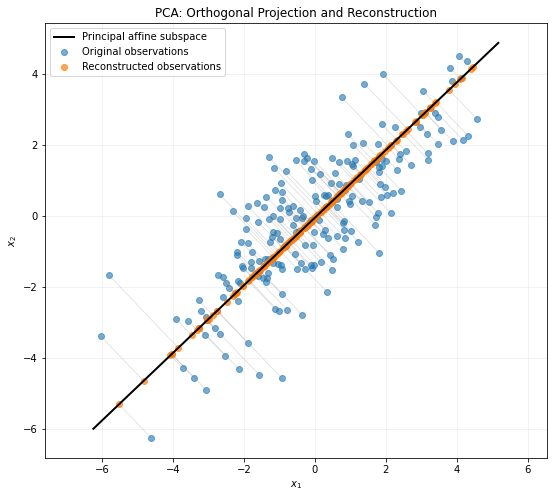

In [12]:
plt.figure(figsize=(9, 8))

# Original observations
plt.scatter(
    X[:, 0], X[:, 1],
    alpha=0.6,
    label="Original observations"
)

# Reconstructed observations
plt.scatter(
    X_reconstructed[:, 0],
    X_reconstructed[:, 1],
    alpha=0.7,
    label="Reconstructed observations"
)

# Reconstruction residuals
for n in range(N):
    plt.plot(
        [X[n, 0], X_reconstructed[n, 0]],
        [X[n, 1], X_reconstructed[n, 1]],
        color="gray",
        alpha=0.25,
        linewidth=0.8
    )

# Principal affine subspace
mean = np.mean(X, axis=0)

t = np.linspace(
    np.min(Z) - 1,
    np.max(Z) + 1,
    200
)

line = mean + np.outer(t, B[:, 0])

plt.plot(
    line[:, 0], line[:, 1],
    color="black",
    linewidth=2,
    label="Principal affine subspace"
)

plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.title("PCA: Orthogonal Projection and Reconstruction")

plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [14]:
#Theoretical loss v.s. reconstructed loss

theoretical_loss = np.sum(eigenvalues[M:])

print("Computed reconstruction loss:", loss)
print("Theoretical reconstruction loss:", theoretical_loss)
print("Are they equal?", np.isclose(loss, theoretical_loss))

Computed reconstruction loss: 0.8317402496062164
Theoretical reconstruction loss: 0.831740249606217
Are they equal? True


### PCA in Higher Dimensions

Let us understand what happens when $K = 10$.

In [15]:
rng = np.random.default_rng(42)

N = 1000
K = 10

# Prescribed population eigenvalues
population_eigenvalues = np.array([
    20, 15, 10, 5, 2, 1, 0.5, 0.2, 0.1, 0.05
])

# Construct a random orthogonal matrix
A = rng.standard_normal((K, K))
Q, _ = np.linalg.qr(A)

# Construct the population covariance matrix
Lambda = np.diag(population_eigenvalues)
Sigma = Q @ Lambda @ Q.T

# Generate the observed dataset
X = rng.multivariate_normal(
    np.zeros(K),
    Sigma,
    size=N
)

print("Shape of dataset:", X.shape)

Shape of dataset: (1000, 10)


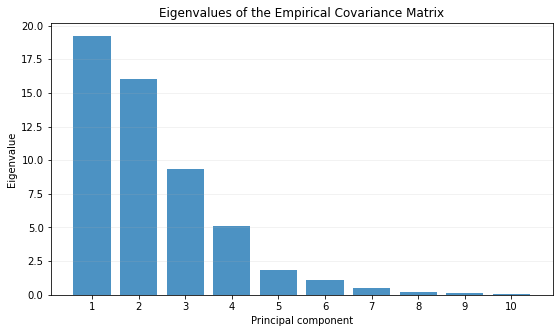

In [17]:
#Visualizing the eigenvalues

Y, mean = center_data(X)
S = covariance_matrix(Y)

eigenvalues, eigenvectors = spectral_decomposition(S)

plt.figure(figsize=(9, 5))

plt.bar(
    np.arange(1, K + 1),
    eigenvalues,
    alpha=0.8
)

plt.xlabel("Principal component")
plt.ylabel("Eigenvalue")
plt.title("Eigenvalues of the Empirical Covariance Matrix")

plt.xticks(np.arange(1, K + 1))
plt.grid(axis="y", alpha=0.2)
plt.show()

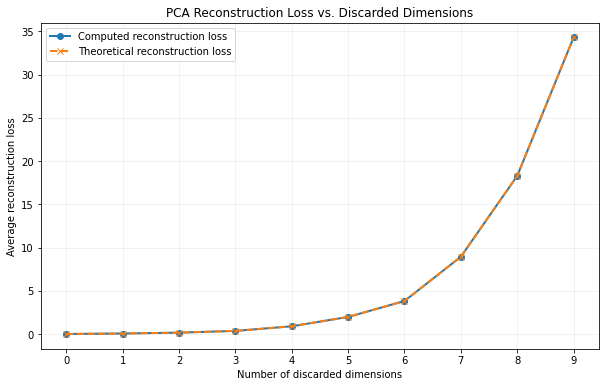

In [21]:
discarded_dimensions = np.arange(0, K)

computed_losses = []
theoretical_losses = []

for d in discarded_dimensions:

    M = K - d

    # Apply PCA
    B, Z, X_reconstructed, loss, eigenvalues = PCA(X, M)

    # Store the computed reconstruction loss
    computed_losses.append(loss)

    # Store the theoretical reconstruction loss
    theoretical_losses.append(np.sum(eigenvalues[M:]))

computed_losses = np.array(computed_losses)
theoretical_losses = np.array(theoretical_losses)

#Plotting the losses as we discard more dimensions

plt.figure(figsize=(10, 6))

plt.plot(
    discarded_dimensions,
    computed_losses,
    marker="o",
    linewidth=2,
    label="Computed reconstruction loss"
)

plt.plot(
    discarded_dimensions,
    theoretical_losses,
    linestyle="--",
    marker="x",
    linewidth=2,
    label="Theoretical reconstruction loss"
)

plt.xlabel("Number of discarded dimensions")
plt.ylabel("Average reconstruction loss")
plt.title("PCA Reconstruction Loss vs. Discarded Dimensions")

plt.xticks(discarded_dimensions)
plt.legend()
plt.grid(alpha=0.2)
plt.show()



Notice that we can discard several dimensions before experiencing a substantial increase in reconstruction loss. However, once we begin discarding directions associated with larger eigenvalues, the reconstruction loss increases rapidly.